# Credit Priority Intelligence System
## Machine Learning Model Development

This notebook follows the instructor's Session 2–3 workflow: data cleaning using the `-99999` sentinel rules, feature screening (VIF, ANOVA and Chi-square), categorical encoding, Decision Tree / Random Forest / XGBoost comparison, and XGBoost tuning.

**Target:** `Approved_Flag` (P1, P2, P3, P4)  
**Identifier:** `PROSPECTID` (excluded from model features)  
**Institution identity:** anonymised

Run all cells from top to bottom.

## 1. Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from scipy.stats import chi2_contingency, f_oneway
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, f1_score
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

import xgboost as xgb

RANDOM_STATE = 42


## 2. Load the two Excel files

In [2]:
df1 = pd.read_excel(r"C:\Users\Mihir Deshpande\Downloads\case_study1.xlsx")
df2 = pd.read_excel(r"C:\Users\Mihir Deshpande\Downloads\case_study2.xlsx")

print("Dataset 1 shape:", df1.shape)
print("Dataset 2 shape:", df2.shape)


Dataset 1 shape: (51336, 26)
Dataset 2 shape: (51336, 62)


## 3. Data cleaning — instructor's sentinel-value rules

In [3]:
# Work on copies
df1 = df1.copy()
df2 = df2.copy()

# Remove records from Dataset 1 where Age_Oldest_TL has the -99999 sentinel
df1 = df1.loc[df1["Age_Oldest_TL"] != -99999].copy()

# In Dataset 2, remove columns containing more than 10,000 sentinel values
columns_to_be_removed = [
    col for col in df2.columns
    if (df2[col] == -99999).sum() > 10000
]
df2 = df2.drop(columns=columns_to_be_removed).copy()

# Then remove records containing the sentinel in the remaining Dataset 2 columns
for col in df2.columns:
    df2 = df2.loc[df2[col] != -99999].copy()

print("Dataset 1 after cleaning:", df1.shape)
print("Dataset 2 after cleaning:", df2.shape)
print("Columns removed from Dataset 2:", columns_to_be_removed)


Dataset 1 after cleaning: (51296, 26)
Dataset 2 after cleaning: (42066, 54)
Columns removed from Dataset 2: ['time_since_first_deliquency', 'time_since_recent_deliquency', 'max_delinquency_level', 'max_deliq_6mts', 'max_deliq_12mts', 'CC_utilization', 'PL_utilization', 'max_unsec_exposure_inPct']


## 4. Merge datasets

In [4]:
df = pd.merge(
    df1,
    df2,
    how="inner",
    on="PROSPECTID",
    validate="one_to_one"
)

print("Merged dataset shape:", df.shape)
print("Total missing values:", int(df.isna().sum().sum()))
display(df.head())


Merged dataset shape: (42064, 79)
Total missing values: 0


,PROSPECTID,Total_TL,Tot_Closed_TL,Tot_Active_TL,Total_TL_opened_L6M,Tot_TL_closed_L6M,pct_tl_open_L6M,pct_tl_closed_L6M,pct_active_tl,pct_closed_tl,...,pct_PL_enq_L6m_of_L12m,pct_CC_enq_L6m_of_L12m,pct_PL_enq_L6m_of_ever,pct_CC_enq_L6m_of_ever,HL_Flag,GL_Flag,last_prod_enq2,first_prod_enq2,Credit_Score,Approved_Flag
0,1,5,4,1,0,0,0.000,0.0,0.200,0.800,...,0.0,0.0,0.000,0.0,1,0,PL,PL,696,P2
1,2,1,0,1,0,0,0.000,0.0,1.000,0.000,...,0.0,0.0,0.000,0.0,0,0,ConsumerLoan,ConsumerLoan,685,P2
2,3,8,0,8,1,0,0.125,0.0,1.000,0.000,...,0.0,0.0,0.000,0.0,1,0,ConsumerLoan,others,693,P2
3,5,3,2,1,0,0,0.000,0.0,0.333,0.667,...,0.0,0.0,0.000,0.0,0,0,AL,AL,753,P1
4,6,6,5,1,0,0,0.000,0.0,0.167,0.833,...,1.0,0.0,0.429,0.0,1,0,ConsumerLoan,PL,668,P3


## 5. Exploratory data analysis

Target distribution:


Approved_Flag
P2    25452
P3     6440
P4     5264
P1     4908
Name: count, dtype: int64

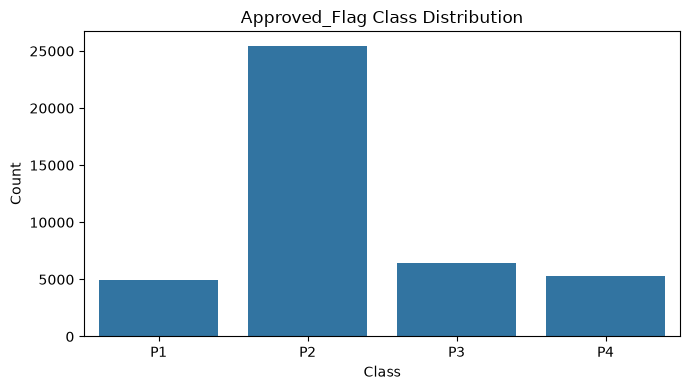

Categorical columns:
['MARITALSTATUS', 'EDUCATION', 'GENDER', 'last_prod_enq2', 'first_prod_enq2', 'Approved_Flag']


In [5]:
print("Target distribution:")
display(df["Approved_Flag"].value_counts())

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Approved_Flag", order=["P1", "P2", "P3", "P4"])
plt.title("Approved_Flag Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

print("Categorical columns:")
categorical_columns = df.select_dtypes(include=["object"]).columns.tolist()
print(categorical_columns)


## 6. Train-test split

The split is performed **before target-informed feature selection**. This keeps the held-out test data out of the feature-screening and model-tuning steps.

In [6]:
TARGET = "Approved_Flag"
ID_COL = "PROSPECTID"

# Keep only the four expected target classes
df = df[df[TARGET].isin(["P1", "P2", "P3", "P4"])].copy()

X_all = df.drop(columns=[TARGET, ID_COL])
y_all = df[TARGET].astype(str)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_all,
    y_all,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_all
)

print("Training shape:", X_train_raw.shape)
print("Testing shape:", X_test_raw.shape)
print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True).sort_index())


Training shape: (33651, 77)
Testing shape: (8413, 77)

Training target distribution:


Approved_Flag
P1    0.116668
P2    0.605093
P3    0.153101
P4    0.125137
Name: proportion, dtype: float64

## 7. Categorical feature screening — Chi-square test (training data only)

In [7]:
categorical_candidates = [
    "MARITALSTATUS", "EDUCATION", "GENDER",
    "last_prod_enq2", "first_prod_enq2"
]

categorical_features = []
chi_square_results = []

for col in categorical_candidates:
    if col in X_train_raw.columns:
        contingency = pd.crosstab(X_train_raw[col], y_train)
        chi2, p_value, _, _ = chi2_contingency(contingency)
        chi_square_results.append({"Feature": col, "Chi2_p_value": p_value})
        if p_value <= 0.05:
            categorical_features.append(col)

chi_square_results = pd.DataFrame(chi_square_results)
display(chi_square_results)
print("Categorical features retained:", categorical_features)


,Feature,Chi2_p_value
0,MARITALSTATUS,2.300048e-184
1,EDUCATION,3.669703e-24
2,GENDER,7.948694e-05
3,last_prod_enq2,0.000000e+00
4,first_prod_enq2,1.420797e-223


Categorical features retained: ['MARITALSTATUS', 'EDUCATION', 'GENDER', 'last_prod_enq2', 'first_prod_enq2']


## 8. Numerical feature screening — VIF (training data only)

In [10]:
# Numerical Feature Selection using VIF

import numpy as np
import pandas as pd
import warnings

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# 1. Select numerical features from training data
numeric_candidates = X_train_raw.select_dtypes(
    include=np.number
).columns.tolist()

vif_data = X_train_raw[numeric_candidates].copy()

# 2. Handle missing and infinite values
vif_data = vif_data.replace([np.inf, -np.inf], np.nan)
vif_data = vif_data.fillna(vif_data.median())

# 3. Remove constant and duplicate columns
vif_data = vif_data.loc[:, vif_data.nunique() > 1]
vif_data = vif_data.loc[:, ~vif_data.T.duplicated()]

# 4. Use a representative sample for faster VIF calculation
vif_data = vif_data.sample(
    n=min(5000, len(vif_data)),
    random_state=42
)

# 5. Standardize numerical features
vif_data = (
    vif_data - vif_data.mean()
) / vif_data.std(ddof=0)

vif_data = vif_data.dropna(axis=1)

# 6. Iteratively remove features with VIF > 6
columns_to_be_kept = vif_data.columns.tolist()

while len(columns_to_be_kept) > 1:

    current_data = vif_data[columns_to_be_kept]

    current_data = add_constant(
        current_data,
        has_constant="add"
    )

    vif_values = []

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        for i, feature in enumerate(columns_to_be_kept, start=1):
            value = variance_inflation_factor(
                current_data.values,
                i
            )
            vif_values.append(value)

    vif_values = np.nan_to_num(
        vif_values,
        nan=np.inf,
        posinf=np.inf
    )

    vif_series = pd.Series(
        vif_values,
        index=columns_to_be_kept
    )

    highest_vif = vif_series.max()

    if highest_vif <= 6:
        break

    feature_to_remove = vif_series.idxmax()

    columns_to_be_kept.remove(feature_to_remove)

    print(
        f"Removed: {feature_to_remove} | "
        f"VIF: {highest_vif:.2f}"
    )

# 7. Final retained numerical features
print("\nNumerical features retained:", len(columns_to_be_kept))
print(columns_to_be_kept)

print("\nFinal VIF values:")

final_vif_data = add_constant(
    vif_data[columns_to_be_kept],
    has_constant="add"
)

final_vif = pd.DataFrame({
    "Feature": columns_to_be_kept,
    "VIF": [
        variance_inflation_factor(final_vif_data.values, i)
        for i in range(1, len(columns_to_be_kept) + 1)
    ]
})

display(final_vif.sort_values("VIF", ascending=False))

Removed: Auto_TL | VIF: 1000799917193443.50
Removed: Total_TL | VIF: 1000799917193443.50
Removed: Tot_Active_TL | VIF: 1000799917193443.50
Removed: pct_active_tl | VIF: 1000799917193443.50
Removed: num_deliq_6mts | VIF: 1000799917193443.50
Removed: Secured_TL | VIF: 135.54
Removed: num_lss_6mts | VIF: 61.90
Removed: Tot_Closed_TL | VIF: 49.70
Removed: enq_L12m | VIF: 24.94
Removed: num_std_12mts | VIF: 22.67
Removed: pct_CC_enq_L6m_of_L12m | VIF: 18.67
Removed: pct_PL_enq_L6m_of_L12m | VIF: 16.68
Removed: enq_L6m | VIF: 12.21
Removed: Unsecured_TL | VIF: 11.86
Removed: PL_enq_L12m | VIF: 11.40
Removed: Total_TL_opened_L12M | VIF: 10.99
Removed: num_times_30p_dpd | VIF: 10.63
Removed: num_deliq_12mts | VIF: 8.21
Removed: Tot_TL_closed_L12M | VIF: 8.19
Removed: CC_enq_L12m | VIF: 7.93
Removed: Credit_Score | VIF: 6.03

Numerical features retained: 49
['Total_TL_opened_L6M', 'Tot_TL_closed_L6M', 'pct_tl_open_L6M', 'pct_tl_closed_L6M', 'pct_closed_tl', 'pct_tl_open_L12M', 'pct_tl_closed_L1

,Feature,VIF
34,PL_enq,5.574258
31,tot_enq,5.572209
35,PL_enq_L6m,5.482085
2,pct_tl_open_L6M,5.152346
18,max_recent_level_of_deliq,5.047003
30,recent_level_of_deliq,4.742944
41,pct_opened_TLs_L6m_of_L12m,4.703969
0,Total_TL_opened_L6M,4.380866
33,CC_enq_L6m,4.236970
32,CC_enq,4.160274


## 9. Numerical feature screening — ANOVA (training data only)

In [11]:
columns_to_be_kept_numerical = []
anova_results = []

for col in columns_to_be_kept:
    values = X_train_raw[col]
    groups = [values[y_train == cls].dropna().values for cls in ["P1", "P2", "P3", "P4"]]

    # ANOVA requires at least one observation in every class.
    if all(len(group) > 0 for group in groups):
        f_statistic, p_value = f_oneway(*groups)
        anova_results.append({
            "Feature": col,
            "F_statistic": f_statistic,
            "p_value": p_value
        })
        if p_value <= 0.05:
            columns_to_be_kept_numerical.append(col)

anova_results = pd.DataFrame(anova_results).sort_values("p_value")
display(anova_results.head(20))
print("Numerical features retained after ANOVA:", len(columns_to_be_kept_numerical))


,Feature,F_statistic,p_value
2,pct_tl_open_L6M,606.060687,0.000000e+00
5,pct_tl_open_L12M,677.092880,0.000000e+00
13,Other_TL,768.938332,0.000000e+00
14,Age_Oldest_TL,5569.901930,0.000000e+00
21,num_std,2737.521144,0.000000e+00
31,tot_enq,1252.505063,0.000000e+00
22,num_std_6mts,2389.959796,0.000000e+00
33,CC_enq_L6m,641.976579,0.000000e+00
36,time_since_recent_enq,1437.376505,0.000000e+00
45,pct_PL_enq_L6m_of_ever,2308.972735,0.000000e+00


Numerical features retained after ANOVA: 46


## 10. Final feature set and categorical encoding

In [12]:
# Use the same feature groups for train and test.
selected_features = columns_to_be_kept_numerical + categorical_features

X_train = X_train_raw[selected_features].copy()
X_test = X_test_raw[selected_features].copy()

# Apply the instructor's ordinal mapping for EDUCATION.
education_mapping = {
    "SSC": 1,
    "12TH": 2,
    "GRADUATE": 3,
    "UNDER GRADUATE": 3,
    "POST-GRADUATE": 4,
    "OTHERS": 1,
    "PROFESSIONAL": 3
}

if "EDUCATION" in selected_features:
    X_train["EDUCATION"] = X_train["EDUCATION"].map(education_mapping)
    X_test["EDUCATION"] = X_test["EDUCATION"].map(education_mapping)

# One-hot encode the remaining nominal categorical columns.
nominal_columns = [
    col for col in categorical_features
    if col != "EDUCATION"
]

X_train = pd.get_dummies(X_train, columns=nominal_columns, dtype=int)
X_test = pd.get_dummies(X_test, columns=nominal_columns, dtype=int)

# Align test columns to training columns; unseen test categories become zero columns.
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

# Fill any missing values created by category mapping or numeric data.
train_medians = X_train.median(numeric_only=True)
X_train = X_train.fillna(train_medians).fillna(0)
X_test = X_test.fillna(train_medians).fillna(0)

print("Final training feature shape:", X_train.shape)
print("Final testing feature shape:", X_test.shape)


Final training feature shape: (33651, 63)
Final testing feature shape: (8413, 63)


## 11. Encode target

In [13]:
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

print("Class encoding:")
for i, class_name in enumerate(label_encoder.classes_):
    print(class_name, ":", i)


Class encoding:
P1 : 0
P2 : 1
P3 : 2
P4 : 3


## 12. Model comparison — Decision Tree, Random Forest and XGBoost

In [14]:
models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=20,
        min_samples_split=10,
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "XGBoost": xgb.XGBClassifier(
        objective="multi:softprob",
        num_class=len(label_encoder.classes_),
        eval_metric="mlogloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

comparison_rows = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train_encoded)
    predictions = model.predict(X_test)

    trained_models[name] = model
    comparison_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_encoded, predictions),
        "Macro_F1": f1_score(y_test_encoded, predictions, average="macro")
    })

model_comparison = pd.DataFrame(comparison_rows).sort_values(
    "Macro_F1", ascending=False
).reset_index(drop=True)

display(model_comparison)


,Model,Accuracy,Macro_F1
0,XGBoost,0.770831,0.678944
1,Random Forest,0.768810,0.659262
2,Decision Tree,0.704148,0.617446


## 13. Hyperparameter tuning — XGBoost

Tuning uses **training data only** with stratified cross-validation. The test set is not used to select hyperparameters.

In [15]:
xgb_base = xgb.XGBClassifier(
    objective="multi:softprob",
    num_class=len(label_encoder.classes_),
    eval_metric="mlogloss",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.05, 0.1, 0.2],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

grid_search = GridSearchCV(
    estimator=xgb_base,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train_encoded)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation macro F1:", round(grid_search.best_score_, 4))


Fitting 3 folds for each of 72 candidates, totalling 216 fits
Best parameters: {'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 100, 'subsample': 0.8}
Best cross-validation macro F1: 0.685


## 14. Final model selection and one-time test evaluation

In [16]:
# Compare the tuned XGBoost CV result with the baseline models' training-CV scores
# by using the tuned XGBoost as the final model for this instructor-aligned workflow.
final_model = grid_search.best_estimator_
final_predictions = final_model.predict(X_test)

accuracy = accuracy_score(y_test_encoded, final_predictions)
precision, recall, class_f1, _ = precision_recall_fscore_support(
    y_test_encoded,
    final_predictions,
    labels=np.arange(len(label_encoder.classes_)),
    zero_division=0
)
macro_f1 = f1_score(y_test_encoded, final_predictions, average="macro")

print("Final model: Tuned XGBoost")
print("Test Accuracy:", round(accuracy, 4))
print("Test Macro F1:", round(macro_f1, 4))
print("\nClassification Report:")
print(classification_report(
    y_test_encoded,
    final_predictions,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))


Final model: Tuned XGBoost
Test Accuracy: 0.7745
Test Macro F1: 0.6828

Classification Report:
              precision    recall  f1-score   support

          P1       0.81      0.76      0.78       982
          P2       0.82      0.91      0.86      5090
          P3       0.44      0.29      0.35      1288
          P4       0.76      0.72      0.74      1053

    accuracy                           0.77      8413
   macro avg       0.71      0.67      0.68      8413
weighted avg       0.75      0.77      0.76      8413



## 15. Confusion matrix

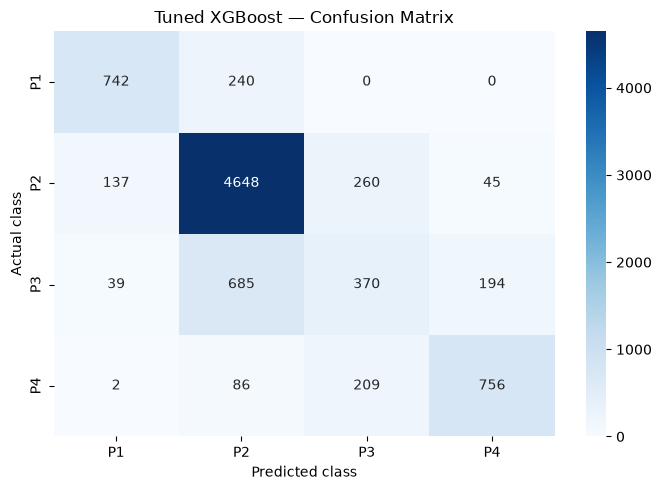

In [17]:
cm = confusion_matrix(
    y_test_encoded,
    final_predictions,
    labels=np.arange(len(label_encoder.classes_))
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.title("Tuned XGBoost — Confusion Matrix")
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.tight_layout()
plt.show()


## 16. Feature importance

,Feature,Importance
35,enq_L3m,0.128568
14,Age_Oldest_TL,0.074935
42,pct_PL_enq_L6m_of_ever,0.051350
17,num_times_delinquent,0.049360
21,num_std,0.048138
34,time_since_recent_enq,0.038175
22,num_std_6mts,0.036768
33,PL_enq_L6m,0.035200
28,recent_level_of_deliq,0.025994
18,max_recent_level_of_deliq,0.025467


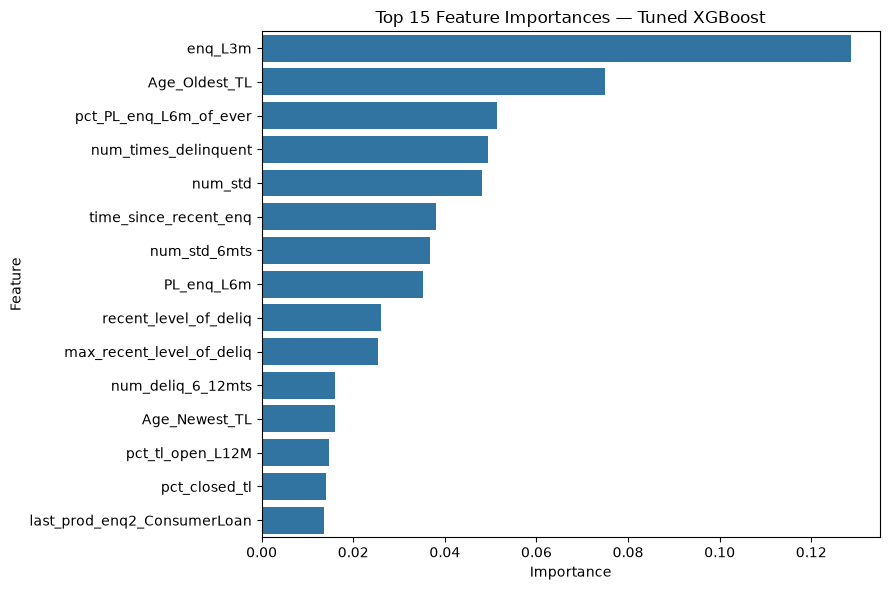

In [18]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": final_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(feature_importance.head(20))

plt.figure(figsize=(9, 6))
sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)
plt.title("Top 15 Feature Importances — Tuned XGBoost")
plt.tight_layout()
plt.show()


## 17. Save model artifacts for the Flask application

In [19]:
# Save the complete trained model and the exact feature order.
with open("model.pkl", "wb") as file:
    pickle.dump(final_model, file)

with open("label_encoder.pkl", "wb") as file:
    pickle.dump(label_encoder, file)

with open("feature_columns.pkl", "wb") as file:
    pickle.dump(X_train.columns.tolist(), file)

print("Model development completed.")
print("Saved: model.pkl, label_encoder.pkl, feature_columns.pkl")
print("Final test accuracy:", round(accuracy, 4))
print("Final test macro F1:", round(macro_f1, 4))


Model development completed.
Saved: model.pkl, label_encoder.pkl, feature_columns.pkl
Final test accuracy: 0.7745
Final test macro F1: 0.6828
